# Blue/red linear: explore `testData`
See `PLANblueredLinear.md`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from scipy.io import loadmat

PATH = "/home/sebas/data/blueRedLinear/blueExpdataStruct_06OCT26.mat"
cells = loadmat(PATH, squeeze_me=True, struct_as_record=False)["testData"]
runs = {str(s.name): s for s in cells}

In [2]:
summary = pd.DataFrame(
    {
        name: {
            "typeRun": int(s.typeRun),
            "n_raw": s.rawData.size,
            "n_baselines": getattr(s, "baselines", np.array([])).size,
            "n_run": s.runData.size,
            "run_mean": s.runData.mean(),
            "run_std": s.runData.std(ddof=1),
        }
        for name, s in runs.items()
    }
).T
summary

,typeRun,n_raw,n_baselines,n_run,run_mean,run_std
BR_NF_1,1.0,16.0,4.0,12.0,1.727368,0.091627
BR_NF_2,1.0,16.0,4.0,12.0,1.704409,0.051510
BR_YF_1,1.0,16.0,4.0,12.0,1.461447,0.116380
BR_YF_2,1.0,16.0,4.0,12.0,1.549573,0.135286
base_NF,2.0,10.0,0.0,10.0,1.548941,0.095299
base_YF,2.0,10.0,0.0,10.0,1.525565,0.102314
BR_LO_NF_1,1.0,16.0,4.0,12.0,1.639686,0.078887
BR_LO_NF_2,1.0,16.0,4.0,12.0,1.512379,0.086973
BR_LO_YF_1,1.0,16.0,4.0,12.0,1.609218,0.087914
BR_LO_YF_2,1.0,16.0,4.0,12.0,1.522261,0.072323


## Inspect a run
Pick a run to see its fields and plot.

In [ ]:
def show(name):
    s = runs[name]
    print({f: np.atleast_1d(getattr(s, f)).shape for f in s._fieldnames})
    fig, ax = plt.subplots(figsize=(8, 3.5))
    x = np.arange(1, s.rawData.size + 1)
    ax.plot(x, s.rawData, "-", color="gray", lw=1)
    if s.typeRun == 1:
        base_idx = np.array([1, 2, s.rawData.size - 1, s.rawData.size])
        run_idx = x[2:-2]
        ax.plot(base_idx, s.baselines, "o", color="tab:blue", label="baselines")
    else:
        run_idx = x
    ax.plot(run_idx, s.runData, "o", color="tab:red", label="runData")
    ax.set(title=name, xlabel="sample", ylabel="value")
    ax.legend()
    plt.show()

widgets.interact(show, name=widgets.Dropdown(options=list(runs), description="run"));

interactive(children=(Dropdown(description='run', options=('BR_NF_1', 'BR_NF_2', 'BR_YF_1', 'BR_YF_2', 'base_N…

## Compare runs
Overlay `rawData` for any selection.

In [ ]:
def overlay(names):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    for n in names:
        ax.plot(runs[n].rawData, "o-", label=n, ms=3)
    ax.set(xlabel="sample", ylabel="value")
    ax.legend(fontsize=7, ncol=2)
    plt.show()

widgets.interact(
    overlay,
    names=widgets.SelectMultiple(options=list(runs), value=list(runs)[:2], rows=12),
);

interactive(children=(SelectMultiple(description='names', index=(0, 1), options=('BR_NF_1', 'BR_NF_2', 'BR_YF_…

In [5]:
baseNF = np.median(runs["base_NF"].runData)
baseYF = np.median(runs["base_YF"].runData)

baseNF_LO = np.median(runs["base_LO_NF"].runData)
baseYF_LO = np.median(runs["base_LO_YF"].runData)

NF_mean = np.mean([runs["BR_NF_1"].runData, runs["BR_NF_2"].runData], axis=0)
YF_mean = np.mean([runs["BR_YF_1"].runData, runs["BR_YF_2"].runData], axis=0)

NF_LO_mean = np.mean([runs["BR_LO_NF_1"].runData, runs["BR_LO_NF_2"].runData], axis=0)
YF_LO_mean = np.mean([runs["BR_LO_YF_1"].runData, runs["BR_LO_YF_1"].runData], axis=0)


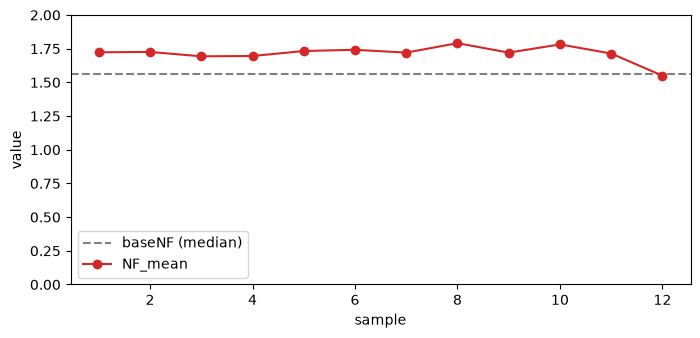

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.axhline(baseNF, color="gray", ls="--", label="baseNF (median)")
ax.plot(np.arange(1, 13), NF_mean.ravel(), "o-", color="tab:red", label="NF_mean")
ax.set(xlabel="sample", ylabel="value")
ax.legend()
ax.set_ylim(0, 2)
plt.show()

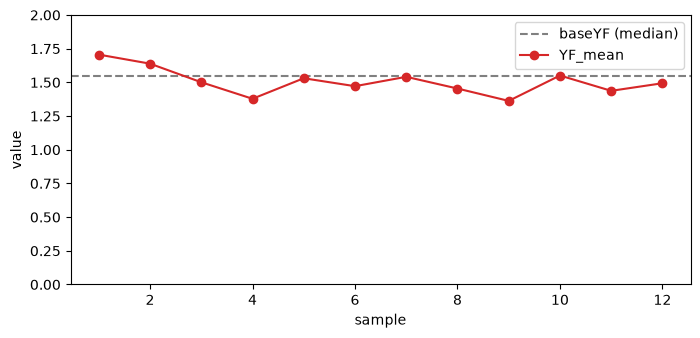

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.axhline(baseYF, color="gray", ls="--", label="baseYF (median)")
ax.plot(np.arange(1, 13), YF_mean.ravel(), "o-", color="tab:red", label="YF_mean")
ax.set(xlabel="sample", ylabel="value")
ax.legend()
ax.set_ylim(0, 2)
plt.show()

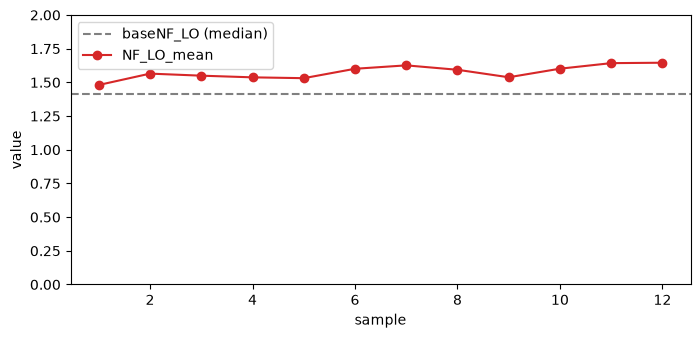

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.axhline(baseNF_LO, color="gray", ls="--", label="baseNF_LO (median)")
ax.plot(np.arange(1, 13), NF_LO_mean.ravel(), "o-", color="tab:red", label="NF_LO_mean")
ax.set(xlabel="sample", ylabel="value")
ax.legend()
ax.set_ylim(0, 2)
plt.show()

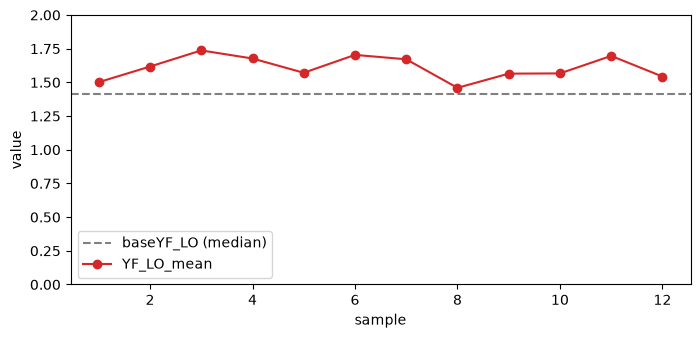

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.axhline(baseYF_LO, color="gray", ls="--", label="baseYF_LO (median)")
ax.plot(np.arange(1, 13), YF_LO_mean.ravel(), "o-", color="tab:red", label="YF_LO_mean")
ax.set(xlabel="sample", ylabel="value")
ax.legend()
ax.set_ylim(0, 2)
plt.show()

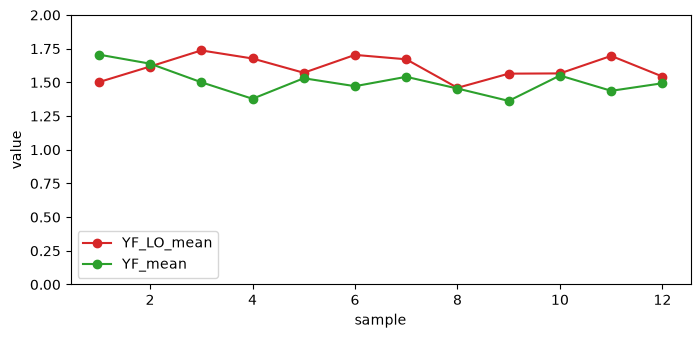

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, 13), YF_LO_mean.ravel(), "o-", color="tab:red", label="YF_LO_mean")
ax.plot(np.arange(1, 13), YF_mean.ravel(), "o-", color="tab:green", label="YF_mean")
ax.set(xlabel="sample", ylabel="value")
ax.legend()
ax.set_ylim(0, 2)
plt.show()

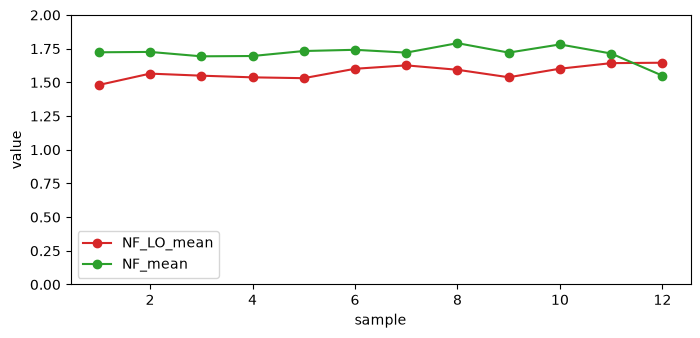

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, 13), NF_LO_mean.ravel(), "o-", color="tab:red", label="NF_LO_mean")
ax.plot(np.arange(1, 13), NF_mean.ravel(), "o-", color="tab:green", label="NF_mean")
ax.set(xlabel="sample", ylabel="value")
ax.legend()
ax.set_ylim(0, 2)
plt.show()

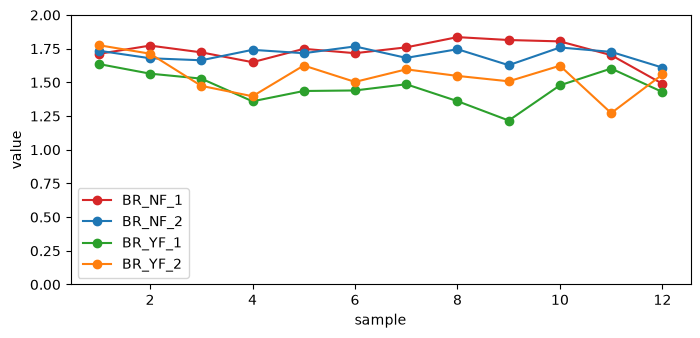

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, 13), runs["BR_NF_1"].runData.ravel(), "o-", color="tab:red", label="BR_NF_1")
ax.plot(np.arange(1, 13), runs["BR_NF_2"].runData.ravel(), "o-", color="tab:blue", label="BR_NF_2")
ax.plot(np.arange(1, 13), runs["BR_YF_1"].runData.ravel(), "o-", color="tab:green", label="BR_YF_1")
ax.plot(np.arange(1, 13), runs["BR_YF_2"].runData.ravel(), "o-", color="tab:orange", label="BR_YF_2")
ax.set(xlabel="sample", ylabel="value")
ax.legend()
ax.set_ylim(0, 2)
plt.show()

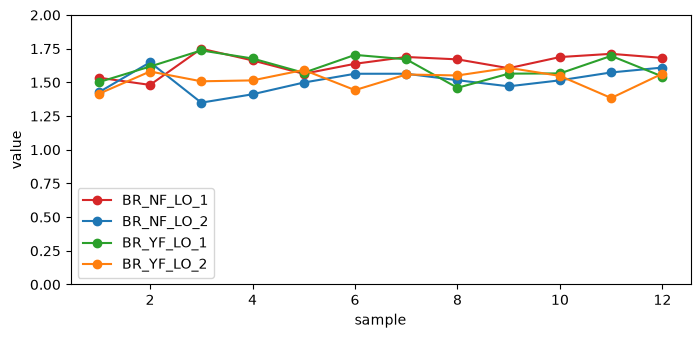

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, 13), runs["BR_LO_NF_1"].runData.ravel(), "o-", color="tab:red", label="BR_NF_LO_1")
ax.plot(np.arange(1, 13), runs["BR_LO_NF_2"].runData.ravel(), "o-", color="tab:blue", label="BR_NF_LO_2")
ax.plot(np.arange(1, 13), runs["BR_LO_YF_1"].runData.ravel(), "o-", color="tab:green", label="BR_YF_LO_1")
ax.plot(np.arange(1, 13), runs["BR_LO_YF_2"].runData.ravel(), "o-", color="tab:orange", label="BR_YF_LO_2")
ax.set(xlabel="sample", ylabel="value")
ax.legend()
ax.set_ylim(0, 2)
plt.show()

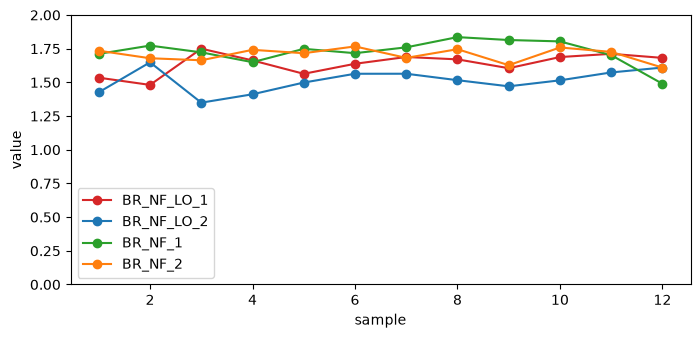

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, 13), runs["BR_LO_NF_1"].runData.ravel(), "o-", color="tab:red", label="BR_NF_LO_1")
ax.plot(np.arange(1, 13), runs["BR_LO_NF_2"].runData.ravel(), "o-", color="tab:blue", label="BR_NF_LO_2")
ax.plot(np.arange(1, 13), runs["BR_NF_1"].runData.ravel(), "o-", color="tab:green", label="BR_NF_1")
ax.plot(np.arange(1, 13), runs["BR_NF_2"].runData.ravel(), "o-", color="tab:orange", label="BR_NF_2")
ax.set(xlabel="sample", ylabel="value")
ax.legend()
ax.set_ylim(0, 2)
plt.show()

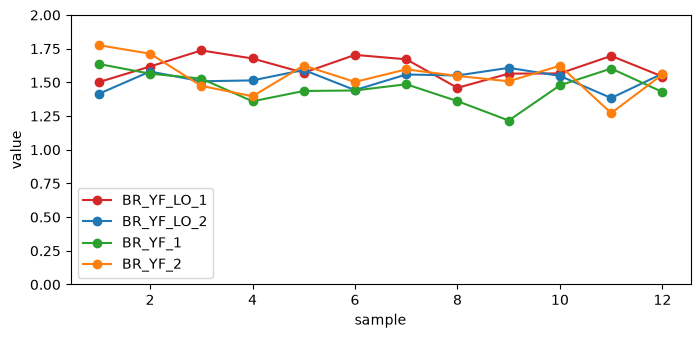

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, 13), runs["BR_LO_YF_1"].runData.ravel(), "o-", color="tab:red", label="BR_YF_LO_1")
ax.plot(np.arange(1, 13), runs["BR_LO_YF_2"].runData.ravel(), "o-", color="tab:blue", label="BR_YF_LO_2")
ax.plot(np.arange(1, 13), runs["BR_YF_1"].runData.ravel(), "o-", color="tab:green", label="BR_YF_1")
ax.plot(np.arange(1, 13), runs["BR_YF_2"].runData.ravel(), "o-", color="tab:orange", label="BR_YF_2")
ax.set(xlabel="sample", ylabel="value")
ax.legend()
ax.set_ylim(0, 2)
plt.show()

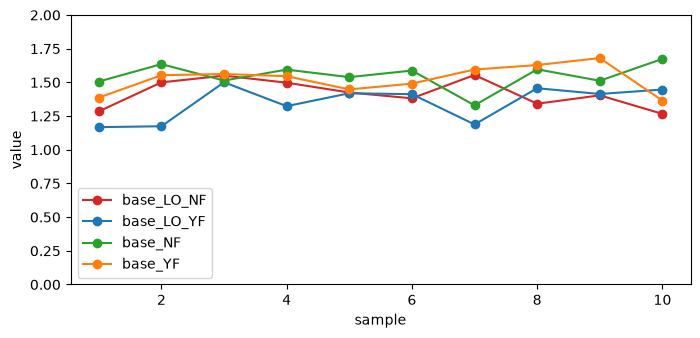

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, 11), runs["base_LO_NF"].runData.ravel(), "o-", color="tab:red", label="base_LO_NF")
ax.plot(np.arange(1, 11), runs["base_LO_YF"].runData.ravel(), "o-", color="tab:blue", label="base_LO_YF")
ax.plot(np.arange(1, 11), runs["base_NF"].runData.ravel(), "o-", color="tab:green", label="base_NF")
ax.plot(np.arange(1, 11), runs["base_YF"].runData.ravel(), "o-", color="tab:orange", label="base_YF")
ax.set(xlabel="sample", ylabel="value")
ax.legend()
ax.set_ylim(0, 2)
plt.show()